<a href="https://colab.research.google.com/github/nevita275/ML_20_Nevita/blob/main/JS08/JS08-Tugas%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN: 20 <br> <br>

# TUGAS LAB 2

## Langkah 1: Import library muat dataset

In [8]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

iris = load_iris()
X, y = iris.data, iris.target

print("Bentuk data:", X.shape)
print("Fitur:", iris.feature_names)
print("Label asli:", [str(n) for n in iris.target_names])

Bentuk data: (150, 4)
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Label asli: ['setosa', 'versicolor', 'virginica']


## Langkah 2: Standarisasi

In [2]:
Xs = StandardScaler().fit_transform(X)

## Langkah 3: Clustering dengan HDBSCAN

In [3]:
hdb = HDBSCAN(min_cluster_size=5).fit(Xs)
labels = hdb.labels_

## Langkah 4: Jumlah cluster dan noise

In [4]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

print("Jumlah cluster :", n_clusters)
print("Jumlah noise   :", n_noise, f"({n_noise/len(labels)*100:.2f}%)")
print(pd.Series(labels).value_counts().sort_index())

Jumlah cluster : 2
Jumlah noise   : 2 (1.33%)
-1     2
 0    50
 1    98
Name: count, dtype: int64


## Langkah 5: Visualisasi dengan PCA

Variansi yang dijelaskan PC1+PC2: 0.9581


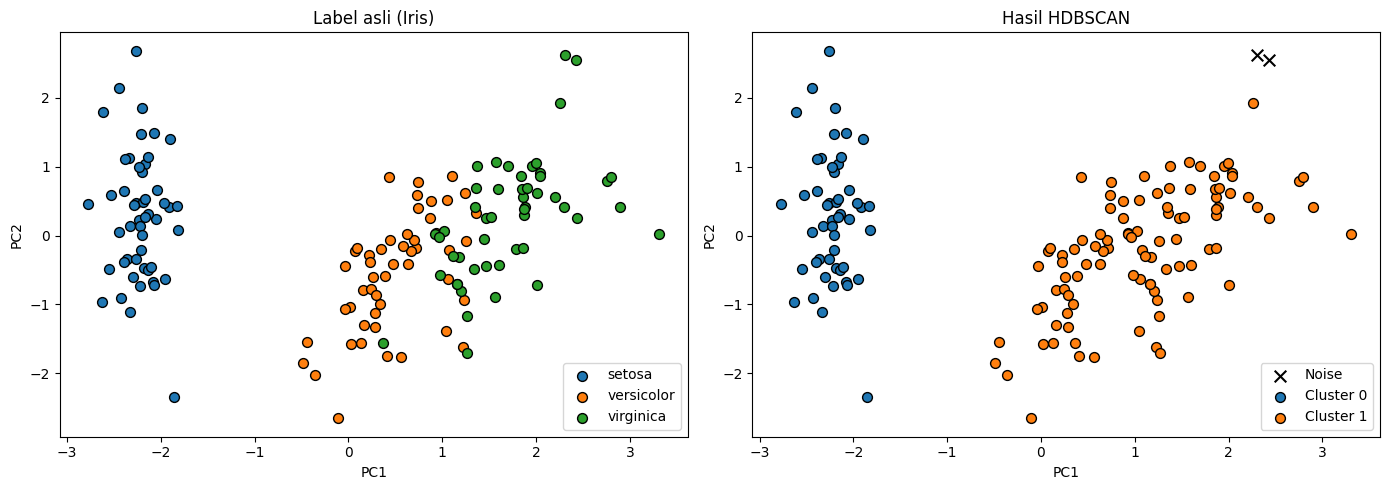

In [5]:
pca = PCA(n_components=2, random_state=0)
Xp = pca.fit_transform(Xs)
print("Variansi yang dijelaskan PC1+PC2:", pca.explained_variance_ratio_.sum().round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Kiri: label asli
for k in sorted(set(y)):
    ax[0].scatter(Xp[y == k, 0], Xp[y == k, 1], label=iris.target_names[k], edgecolor="k", s=50)
ax[0].set_title("Label asli (Iris)")
ax[0].legend()

# Kanan: hasil HDBSCAN
for k in sorted(set(labels)):
    m = labels == k
    if k == -1:
        ax[1].scatter(Xp[m, 0], Xp[m, 1], c="black", marker="x", s=70, label="Noise")
    else:
        ax[1].scatter(Xp[m, 0], Xp[m, 1], label=f"Cluster {k}", edgecolor="k", s=50)
ax[1].set_title("Hasil HDBSCAN")
ax[1].legend()

for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.tight_layout()
plt.show()

## Langkah 6: Perbandingan dengan label asli

In [6]:
# Tabel silang: baris = label asli, kolom = cluster HDBSCAN
tabel = pd.crosstab(
    pd.Series(y, name="Label asli").map(dict(enumerate(iris.target_names))),
    pd.Series(labels, name="Cluster HDBSCAN"),
)
display(tabel)

print("Adjusted Rand Index (ARI):", round(adjusted_rand_score(y, labels), 4))
print("Normalized Mutual Info   :", round(normalized_mutual_info_score(y, labels), 4))

Cluster HDBSCAN,-1,0,1
Label asli,,,
setosa,0,50,0
versicolor,0,0,50
virginica,2,0,48


Adjusted Rand Index (ARI): 0.5638
Normalized Mutual Info   : 0.7175


## Langkah 7: Pengaruh min_cluster_size

In [7]:
hasil = []
for mcs in (3, 5, 10, 15, 20, 30):
    l = HDBSCAN(min_cluster_size=mcs).fit(Xs).labels_
    hasil.append((mcs,
                  len(set(l)) - (1 if -1 in l else 0),
                  int((l == -1).sum()),
                  round(adjusted_rand_score(y, l), 4)))
display(pd.DataFrame(hasil, columns=["min_cluster_size", "jumlah_cluster", "noise", "ARI"]))

,min_cluster_size,jumlah_cluster,noise,ARI
0,3,2,0,0.5681
1,5,2,2,0.5638
2,10,2,2,0.5638
3,15,2,4,0.5438
4,20,2,6,0.5379
5,30,2,12,0.5055


## Analisis Hasil

HDBSCAN membentuk 2 cluster dan menandai 2 sampel (1,33%) sebagai noise,
sedangkan label asli Iris memiliki 3 spesies. Hasilnya hanya sebagian sesuai.

Setosa terpisah sempurna: seluruh 50 sampelnya masuk Cluster 0 tanpa campuran.
Versicolor dan virginica digabung ke Cluster 1 (98 sampel) karena pada plot PCA
keduanya saling tumpang tindih dan tidak ada celah kepadatan di antaranya.
HDBSCAN berbasis densitas, sehingga melihatnya sebagai satu wilayah padat.

Dua titik noise adalah sampel virginica yang berada di ujung sebaran data.
ARI = 0,5638 dan NMI = 0,7175 menunjukkan kecocokan sedang. Perubahan
min_cluster_size dari 3 sampai 30 tidak mengubah jumlah cluster (tetap 2),
hanya menambah jumlah noise dan menurunkan ARI.

Kesimpulan: HDBSCAN baik memisahkan setosa dari spesies lain, tetapi tidak
dapat membedakan versicolor dan virginica karena keduanya tidak terpisah
berdasarkan kepadatan.